### 26-08-26-Part 2

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_parquet("df_final_processed.parquet")

In [3]:
df.head()

,Log_ID,TBM_Timestamp,Tunnel_Section,Contractor_Name,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,status
0,TBM-LOG-0000002,2023-01-01 00:00:00+00:00,HighSpeed_Rail_Link,Apex_Drilling,5.425898,0,TBM-SENS-5410,616.229980,157.660004,40.500000,OK
1,TBM-LOG-0000007,2023-01-01 00:05:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,2.993575,0,TBM-SENS-8004,726.419983,288.799988,62.570000,OK
2,TBM-LOG-0000014,2023-01-01 00:12:00+00:00,HighSpeed_Rail_Link,Titan_Excavators,2.742072,0,TBM-SENS-8906,1071.800049,163.740005,43.000000,OK
3,TBM-LOG-0000023,2023-01-01 00:24:00+00:00,HighSpeed_Rail_Link,Phantom_Boring_LLC,4.853213,0,TBM-SENS-2693,733.659973,158.250000,41.849998,OK
4,TBM-LOG-0000027,2023-01-01 00:27:00+00:00,HighSpeed_Rail_Link,Global_Tunnels,3.534157,0,TBM-SENS-1710,849.030029,262.470001,57.200001,OK


In [4]:
df.dtypes

Log_ID                                 str
TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                           int64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [5]:
df.isnull().sum()

Log_ID                      0
TBM_Timestamp          500345
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar                0
thermal_c                   0
status                      0
dtype: int64

#### EDA with Timestamps

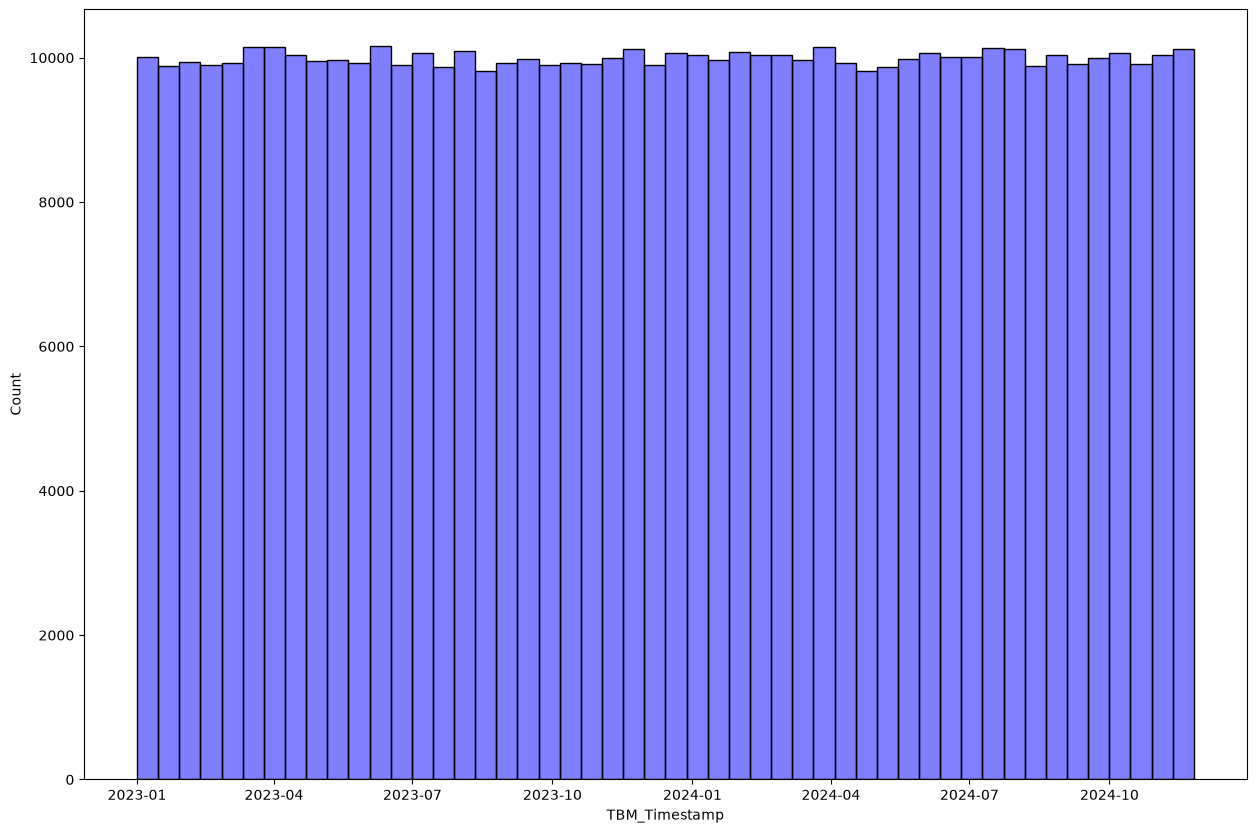

In [6]:
plt.figure(figsize=(15,10))
sns.histplot( df['TBM_Timestamp'], color = 'blue', alpha =0.5, bins= 50)
plt.show()

In [7]:
 df['TBM_Timestamp'].isnull

<bound method Series.isnull of 0        2023-01-01 00:00:00+00:00
1        2023-01-01 00:05:00+00:00
2        2023-01-01 00:12:00+00:00
3        2023-01-01 00:24:00+00:00
4        2023-01-01 00:27:00+00:00
                    ...           
999995                         NaT
999996                         NaT
999997                         NaT
999998                         NaT
999999                         NaT
Name: TBM_Timestamp, Length: 1000000, dtype: datetime64[us, UTC]>

In [8]:
time = df['TBM_Timestamp']
is_nan = time.isna()
groups = is_nan.ne(is_nan.shift()).cumsum()

nan_blocks = (df[is_nan].groupby(groups[is_nan]).agg(
        start_index=('TBM_Timestamp', lambda x: x.index.min()),
        end_index=('TBM_Timestamp', lambda x: x.index.max()),
        missing_count=('TBM_Timestamp', "size")).sort_values("missing_count", ascending=False))
print(nan_blocks)

               start_index  end_index  missing_count
TBM_Timestamp                                       
6                   625537     750899         125363
4                   375771     500985         125215
2                   124659     249561         124903
8                   875136     999999         124864


In [9]:
time_df = pd.DataFrame()
time_df = df.sort_values("TBM_Timestamp").reset_index(drop=True)
time_df["time_gap"] = time_df["TBM_Timestamp"].diff()
time_df["gap_minutes"] = time_df["time_gap"].dt.total_seconds() / 60

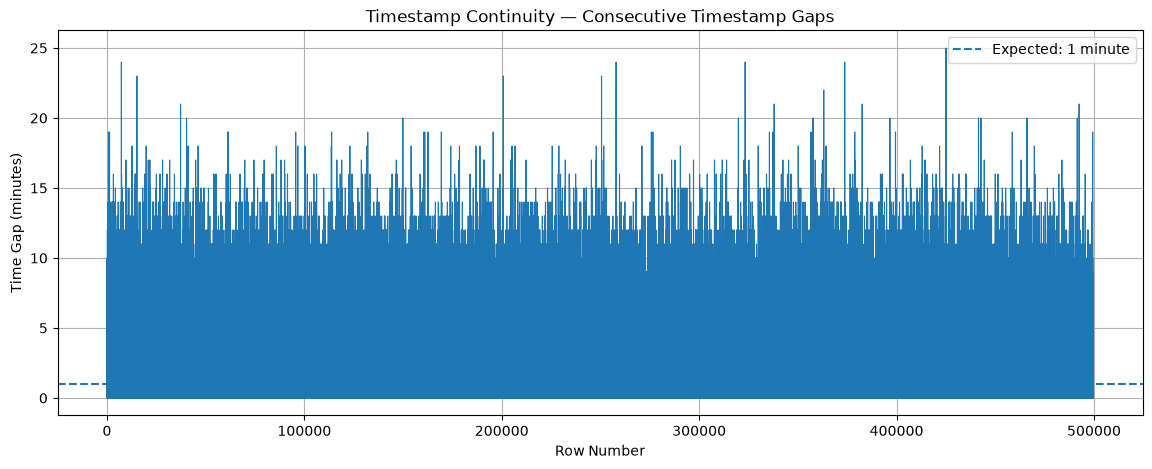

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(time_df.index, time_df["gap_minutes"], linewidth=0.8)

plt.axhline(1, linestyle="--", label="Expected: 1 minute")

plt.xlabel("Row Number")
plt.ylabel("Time Gap (minutes)")
plt.title("Timestamp Continuity — Consecutive Timestamp Gaps")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
gaps = time_df[time_df["gap_minutes"] > 1].copy()
print(gaps[["TBM_Timestamp", "gap_minutes"]].head(20))

               TBM_Timestamp  gap_minutes
1  2023-01-01 00:03:00+00:00          3.0
2  2023-01-01 00:05:00+00:00          2.0
5  2023-01-01 00:11:00+00:00          4.0
8  2023-01-01 00:19:00+00:00          7.0
11 2023-01-01 00:24:00+00:00          3.0
12 2023-01-01 00:27:00+00:00          3.0
15 2023-01-01 00:33:00+00:00          4.0
17 2023-01-01 00:39:00+00:00          5.0
18 2023-01-01 00:42:00+00:00          3.0
21 2023-01-01 00:48:00+00:00          4.0
22 2023-01-01 00:50:00+00:00          2.0
23 2023-01-01 00:57:00+00:00          7.0
24 2023-01-01 00:59:00+00:00          2.0
28 2023-01-01 01:09:00+00:00          9.0
29 2023-01-01 01:12:00+00:00          3.0
30 2023-01-01 01:15:00+00:00          3.0
31 2023-01-01 01:20:00+00:00          5.0
33 2023-01-01 01:26:00+00:00          5.0
34 2023-01-01 01:28:00+00:00          2.0
35 2023-01-01 01:30:00+00:00          2.0


In [12]:
print("Total rows:", len(time_df))
print("Missing timestamps:", time_df["TBM_Timestamp"].isna().sum())
print("Number of gaps:", (time_df["gap_minutes"] > 1).sum())
print("Largest gap:", time_df["gap_minutes"].max(), "minutes")

print("\nMissing values by column:")
print(time_df.isna().sum().sort_values(ascending=False))

Total rows: 1000000
Missing timestamps: 500345
Number of gaps: 238519
Largest gap: 25.0 minutes

Missing values by column:
time_gap               500346
gap_minutes            500346
TBM_Timestamp          500345
Log_ID                      0
Tunnel_Section              0
Target_Advance_Rate         0
Contractor_Name             0
Is_Spoofed                  0
sensor_hex                  0
pressure_bar                0
torque_knm                  0
status                      0
thermal_c                   0
dtype: int64


In [13]:
print(df[df["TBM_Timestamp"].isna()].head(10).to_string())

                 Log_ID TBM_Timestamp       Tunnel_Section     Contractor_Name  Target_Advance_Rate  Is_Spoofed     sensor_hex   torque_knm  pressure_bar  thermal_c status
124659  TBM-LOG-0133239           NaT  HighSpeed_Rail_Link    Titan_Excavators             5.451903           0  TBM-SENS-8148   661.179993    167.029999  58.610001     OK
124660  TBM-LOG-0514321           NaT  HighSpeed_Rail_Link  Phantom_Boring_LLC             1.386316           0  TBM-SENS-7689  1010.130005    279.700012  61.009998     OK
124661  TBM-LOG-0451169           NaT  HighSpeed_Rail_Link       Apex_Drilling             3.568897           0  TBM-SENS-4756   737.270020    267.149994  51.709999     OK
124662  TBM-LOG-0003007           NaT  HighSpeed_Rail_Link  Phantom_Boring_LLC             3.598135           0  TBM-SENS-7068   877.580017    193.699997  57.840000     OK
124663  TBM-LOG-0482543           NaT  HighSpeed_Rail_Link       Apex_Drilling             1.000000           0  TBM-SENS-3617  1145.910034 

In [14]:
print(df[df["TBM_Timestamp"].notna()].head(10).to_string())

            Log_ID             TBM_Timestamp       Tunnel_Section     Contractor_Name  Target_Advance_Rate  Is_Spoofed     sensor_hex   torque_knm  pressure_bar  thermal_c status
0  TBM-LOG-0000002 2023-01-01 00:00:00+00:00  HighSpeed_Rail_Link       Apex_Drilling             5.425898           0  TBM-SENS-5410   616.229980    157.660004  40.500000     OK
1  TBM-LOG-0000007 2023-01-01 00:05:00+00:00  HighSpeed_Rail_Link  Phantom_Boring_LLC             2.993575           0  TBM-SENS-8004   726.419983    288.799988  62.570000     OK
2  TBM-LOG-0000014 2023-01-01 00:12:00+00:00  HighSpeed_Rail_Link    Titan_Excavators             2.742072           0  TBM-SENS-8906  1071.800049    163.740005  43.000000     OK
3  TBM-LOG-0000023 2023-01-01 00:24:00+00:00  HighSpeed_Rail_Link  Phantom_Boring_LLC             4.853213           0  TBM-SENS-2693   733.659973    158.250000  41.849998     OK
4  TBM-LOG-0000027 2023-01-01 00:27:00+00:00  HighSpeed_Rail_Link      Global_Tunnels             3.53415

In [15]:
print(df[["Log_ID", "TBM_Timestamp", "Tunnel_Section"]].head(20).to_string())

             Log_ID             TBM_Timestamp       Tunnel_Section
0   TBM-LOG-0000002 2023-01-01 00:00:00+00:00  HighSpeed_Rail_Link
1   TBM-LOG-0000007 2023-01-01 00:05:00+00:00  HighSpeed_Rail_Link
2   TBM-LOG-0000014 2023-01-01 00:12:00+00:00  HighSpeed_Rail_Link
3   TBM-LOG-0000023 2023-01-01 00:24:00+00:00  HighSpeed_Rail_Link
4   TBM-LOG-0000027 2023-01-01 00:27:00+00:00  HighSpeed_Rail_Link
5   TBM-LOG-0000029 2023-01-01 00:29:00+00:00  HighSpeed_Rail_Link
6   TBM-LOG-0000032 2023-01-01 00:33:00+00:00  HighSpeed_Rail_Link
7   TBM-LOG-0000040 2023-01-01 00:44:00+00:00  HighSpeed_Rail_Link
8   TBM-LOG-0000041 2023-01-01 00:48:00+00:00  HighSpeed_Rail_Link
9   TBM-LOG-0000050 2023-01-01 00:59:00+00:00  HighSpeed_Rail_Link
10  TBM-LOG-0000078 2023-01-01 01:37:00+00:00  HighSpeed_Rail_Link
11  TBM-LOG-0000080 2023-01-01 01:38:00+00:00  HighSpeed_Rail_Link
12  TBM-LOG-0000096 2023-01-01 01:54:00+00:00  HighSpeed_Rail_Link
13  TBM-LOG-0000099 2023-01-01 01:55:00+00:00  HighSpeed_Rail_

#### Deal with timestamp with 1 minutes of gap as ideal

In [16]:
df_ts = df.dropna(subset=["TBM_Timestamp"]).copy()

In [17]:
df_ts = df_ts.sort_values("TBM_Timestamp").reset_index(drop=True)

In [18]:
df_ts = df_ts.drop_duplicates(subset=["TBM_Timestamp"],keep="first").reset_index(drop=True)

In [19]:
full_time = pd.date_range(
    start=df_ts["TBM_Timestamp"].min(),
    end=df_ts["TBM_Timestamp"].max(),
    freq="1min",
    tz="UTC"
)

In [20]:
df_ts = (
    df_ts
    .set_index("TBM_Timestamp")
    .reindex(full_time)
)

In [21]:
df_ts.index.name = "TBM_Timestamp"
df_ts = df_ts.reset_index()

In [22]:
timestamp_gap = df_ts["TBM_Timestamp"].diff()

print("Total rows:", len(df_ts))
print("Missing timestamps:", df_ts["TBM_Timestamp"].isna().sum())
print("Largest timestamp gap:", timestamp_gap.max())

print("\nTimestamp intervals:")
print(timestamp_gap.value_counts().head())

Total rows: 999997
Missing timestamps: 0
Largest timestamp gap: 0 days 00:01:00

Timestamp intervals:
TBM_Timestamp
0 days 00:01:00    999996
Name: count, dtype: int64


In [23]:
df_ts['TBM_Timestamp'].isnull().sum()

np.int64(0)

#### Now fill the missing value in the categorical as well numerical varibale after reindexing.

In [24]:
df_ts.dtypes

TBM_Timestamp          datetime64[us, UTC]
Log_ID                                 str
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                         float64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [25]:
df_ts.nunique()

TBM_Timestamp          999997
Log_ID                 393335
Tunnel_Section              4
Contractor_Name             4
Target_Advance_Rate    379280
Is_Spoofed                  2
sensor_hex               9000
torque_knm              92906
pressure_bar            57058
thermal_c               13978
status                      2
dtype: int64

In [26]:
df_ts.isnull().sum()

TBM_Timestamp               0
Log_ID                 606662
Tunnel_Section         606662
Contractor_Name        606662
Target_Advance_Rate    606662
Is_Spoofed             606662
sensor_hex             606662
torque_knm             606662
pressure_bar           606662
thermal_c              606662
status                 606662
dtype: int64

In [27]:
# Columns to interpolate
numeric_cols = [
    "Target_Advance_Rate",
    "torque_knm",
    "pressure_bar",
    "thermal_c"
]

# Interpolate numeric sensor values
df_ts[numeric_cols] = (
    df_ts[numeric_cols]
    .interpolate(method="linear", limit=5)
)

# Fill remaining numeric NaNs at the beginning/end
df_ts[numeric_cols] = (
    df_ts[numeric_cols]
    .ffill()
    .bfill()
)

In [28]:
categorical_cols = [
    "Contractor_Name",
    "Tunnel_Section",
    "Is_Spoofed",
    "sensor_hex",
    "status"
]

df_ts[categorical_cols] = (
    df_ts[categorical_cols]
    .ffill()
    .bfill()
)

In [29]:
df_ts.isnull().sum()

TBM_Timestamp               0
Log_ID                 606662
Tunnel_Section              0
Contractor_Name             0
Target_Advance_Rate         0
Is_Spoofed                  0
sensor_hex                  0
torque_knm                  0
pressure_bar                0
thermal_c                   0
status                      0
dtype: int64

#### Now time to do the One-hot encoding and target encoding.

In [30]:
# No need of Log_ID
df_ts = df_ts.drop(columns=["Log_ID"])

In [31]:
df_ts.isnull().sum()

TBM_Timestamp          0
Tunnel_Section         0
Contractor_Name        0
Target_Advance_Rate    0
Is_Spoofed             0
sensor_hex             0
torque_knm             0
pressure_bar           0
thermal_c              0
status                 0
dtype: int64

In [32]:
df_ts.dtypes

TBM_Timestamp          datetime64[us, UTC]
Tunnel_Section                         str
Contractor_Name                        str
Target_Advance_Rate                float32
Is_Spoofed                         float64
sensor_hex                             str
torque_knm                         float32
pressure_bar                       float32
thermal_c                          float32
status                                 str
dtype: object

In [33]:
df_ts["sensor_hex"]

0         TBM-SENS-5410
1         TBM-SENS-5410
2         TBM-SENS-5410
3         TBM-SENS-4518
4         TBM-SENS-4518
              ...      
999992    TBM-SENS-1596
999993    TBM-SENS-1596
999994    TBM-SENS-1596
999995    TBM-SENS-1596
999996    TBM-SENS-3067
Name: sensor_hex, Length: 999997, dtype: str

In [34]:
print(df_ts["sensor_hex"].nunique())

9000


In [35]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [36]:
categorical_cols = [
    "Contractor_Name",
    "Tunnel_Section",
    "status"
]

In [37]:
encoded = encoder.fit_transform(
    df_ts[categorical_cols]
)

In [38]:
encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df_ts.index
)

In [39]:
# Drop original categorical columns
df_ts = df_ts.drop(columns=categorical_cols)

In [40]:
df_ts = pd.concat(
    [df_ts, encoded_df],
    axis=1
)

In [41]:
df_ts.head()

,TBM_Timestamp,Target_Advance_Rate,Is_Spoofed,sensor_hex,torque_knm,pressure_bar,thermal_c,Contractor_Name_Apex_Drilling,Contractor_Name_Global_Tunnels,Contractor_Name_Phantom_Boring_LLC,Contractor_Name_Titan_Excavators,Tunnel_Section_HighSpeed_Rail_Link,Tunnel_Section_Metro_Line_A,Tunnel_Section_Metro_Line_B,Tunnel_Section_Undersea_Cable_Core,status_OK,status_WARN
0,2023-01-01 00:00:00+00:00,5.425898,0.0,TBM-SENS-5410,616.229980,157.660004,40.500000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2023-01-01 00:01:00+00:00,4.740957,0.0,TBM-SENS-5410,710.566650,190.263336,40.343334,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,2023-01-01 00:02:00+00:00,4.056016,0.0,TBM-SENS-5410,804.903320,222.866669,40.186665,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,2023-01-01 00:03:00+00:00,3.371075,0.0,TBM-SENS-4518,899.239990,255.470001,40.029999,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,2023-01-01 00:04:00+00:00,3.182325,0.0,TBM-SENS-4518,812.829956,272.135010,51.299999,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [42]:
df_ts.shape

(999997, 17)

In [43]:
df_ts.dtypes

TBM_Timestamp                         datetime64[us, UTC]
Target_Advance_Rate                               float32
Is_Spoofed                                        float64
sensor_hex                                            str
torque_knm                                        float32
pressure_bar                                      float32
thermal_c                                         float32
Contractor_Name_Apex_Drilling                     float64
Contractor_Name_Global_Tunnels                    float64
Contractor_Name_Phantom_Boring_LLC                float64
Contractor_Name_Titan_Excavators                  float64
Tunnel_Section_HighSpeed_Rail_Link                float64
Tunnel_Section_Metro_Line_A                       float64
Tunnel_Section_Metro_Line_B                       float64
Tunnel_Section_Undersea_Cable_Core                float64
status_OK                                         float64
status_WARN                                       float64
dtype: object

In [44]:
from sklearn.preprocessing import LabelEncoder
sensor_encoder = LabelEncoder()
df_ts["sensor_id"] = sensor_encoder.fit_transform(df_ts["sensor_hex"].astype(str))

In [45]:
df_ts.dtypes

TBM_Timestamp                         datetime64[us, UTC]
Target_Advance_Rate                               float32
Is_Spoofed                                        float64
sensor_hex                                            str
torque_knm                                        float32
pressure_bar                                      float32
thermal_c                                         float32
Contractor_Name_Apex_Drilling                     float64
Contractor_Name_Global_Tunnels                    float64
Contractor_Name_Phantom_Boring_LLC                float64
Contractor_Name_Titan_Excavators                  float64
Tunnel_Section_HighSpeed_Rail_Link                float64
Tunnel_Section_Metro_Line_A                       float64
Tunnel_Section_Metro_Line_B                       float64
Tunnel_Section_Undersea_Cable_Core                float64
status_OK                                         float64
status_WARN                                       float64
sensor_id     

In [46]:
# No need of sensor_hex
df_ts = df_ts.drop(columns=["sensor_hex"])

In [47]:
df_ts.dtypes

TBM_Timestamp                         datetime64[us, UTC]
Target_Advance_Rate                               float32
Is_Spoofed                                        float64
torque_knm                                        float32
pressure_bar                                      float32
thermal_c                                         float32
Contractor_Name_Apex_Drilling                     float64
Contractor_Name_Global_Tunnels                    float64
Contractor_Name_Phantom_Boring_LLC                float64
Contractor_Name_Titan_Excavators                  float64
Tunnel_Section_HighSpeed_Rail_Link                float64
Tunnel_Section_Metro_Line_A                       float64
Tunnel_Section_Metro_Line_B                       float64
Tunnel_Section_Undersea_Cable_Core                float64
status_OK                                         float64
status_WARN                                       float64
sensor_id                                           int64
dtype: object

In [48]:
# Convert float64 → float32
float_cols = df_ts.select_dtypes(include=["float64"]).columns
df_ts[float_cols] = df_ts[float_cols].astype("float32")

In [49]:
df_ts.dtypes

TBM_Timestamp                         datetime64[us, UTC]
Target_Advance_Rate                               float32
Is_Spoofed                                        float32
torque_knm                                        float32
pressure_bar                                      float32
thermal_c                                         float32
Contractor_Name_Apex_Drilling                     float32
Contractor_Name_Global_Tunnels                    float32
Contractor_Name_Phantom_Boring_LLC                float32
Contractor_Name_Titan_Excavators                  float32
Tunnel_Section_HighSpeed_Rail_Link                float32
Tunnel_Section_Metro_Line_A                       float32
Tunnel_Section_Metro_Line_B                       float32
Tunnel_Section_Undersea_Cable_Core                float32
status_OK                                         float32
status_WARN                                       float32
sensor_id                                           int64
dtype: object

#### Now time to preprocess the data

In [50]:
# ---------------------------------------------------------
# 3. Create cyclical time features
# ---------------------------------------------------------

# Hour of day
df_ts["hour_sin"] = np.sin(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.hour / 24
).astype(np.float32)

df_ts["hour_cos"] = np.cos(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.hour / 24
).astype(np.float32)

# Day of week
df_ts["dayofweek_sin"] = np.sin(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.dayofweek / 7
).astype(np.float32)

df_ts["dayofweek_cos"] = np.cos(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.dayofweek / 7
).astype(np.float32)

# Minute within hour
df_ts["minute_sin"] = np.sin(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.minute / 60
).astype(np.float32)

df_ts["minute_cos"] = np.cos(
    2 * np.pi * df_ts["TBM_Timestamp"].dt.minute / 60
).astype(np.float32)

In [51]:
df_ts.dtypes

TBM_Timestamp                         datetime64[us, UTC]
Target_Advance_Rate                               float32
Is_Spoofed                                        float32
torque_knm                                        float32
pressure_bar                                      float32
thermal_c                                         float32
Contractor_Name_Apex_Drilling                     float32
Contractor_Name_Global_Tunnels                    float32
Contractor_Name_Phantom_Boring_LLC                float32
Contractor_Name_Titan_Excavators                  float32
Tunnel_Section_HighSpeed_Rail_Link                float32
Tunnel_Section_Metro_Line_A                       float32
Tunnel_Section_Metro_Line_B                       float32
Tunnel_Section_Undersea_Cable_Core                float32
status_OK                                         float32
status_WARN                                       float32
sensor_id                                           int64
hour_sin      

In [52]:
## No need of TBM_Timestamp
df_ts = df_ts.drop(columns=["TBM_Timestamp"])

In [53]:
%pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [54]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [55]:
target = df_ts["Is_Spoofed"].astype("float32")
sensor = df_ts["sensor_id"].astype("int64")
numeric = df_ts.drop(columns=["Is_Spoofed", "sensor_id"]).copy()
numeric = numeric.astype("float32")

time_steps = 60

In [56]:
# Create LSTM Sequence
X_numeric = []
X_sensor = []
y = []

numeric_data = numeric.values
sensor_data = sensor.values
target_data = target.values

In [57]:
for i in range(len(df_ts) - time_steps):

    # 60 minutes × numerical features
    X_numeric.append(
        numeric_data[i:i + time_steps]
    )

    # 60 sensor IDs
    X_sensor.append(
        sensor_data[i:i + time_steps]
    )

    # Target immediately after the 60-minute window
    y.append(
        target_data[i + time_steps]
    )

In [58]:
## convert to nparray

In [59]:
X_numeric = np.asarray(
    X_numeric,
    dtype=np.float32
)

X_sensor = np.asarray(
    X_sensor,
    dtype=np.int64
)

y = np.asarray(
    y,
    dtype=np.int64
)

In [60]:
# CHECK SHAPES

print("X_numeric:", X_numeric.shape)
print("X_sensor :", X_sensor.shape)
print("y        :", y.shape)

X_numeric: (999937, 60, 20)
X_sensor : (999937, 60)
y        : (999937,)


### Implement the AI's custom DataLoader class.

In [61]:
n = len(df_ts)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_ts.iloc[:train_end].copy()
val_df = df_ts.iloc[train_end:val_end].copy()
test_df = df_ts.iloc[val_end:].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (699997, 22)
Validation: (150000, 22)
Test: (150000, 22)


In [62]:
from torch.utils.data import Dataset, DataLoader

In [64]:
class TBMTimeSeriesDataset(Dataset):

    def __init__(
        self,
        df,
        numeric_features,
        target_col="Is_Spoofed",
        time_steps=60
    ):
        self.numeric_data = torch.tensor(
            df[numeric_features].values,
            dtype=torch.float32
        )

        self.sensor_data = torch.tensor(
            df["sensor_id"].values,
            dtype=torch.long
        )

        self.target_data = torch.tensor(
            df[target_col].values,
            dtype=torch.long
        )

        self.time_steps = time_steps

    def __len__(self):
        return len(self.numeric_data) - self.time_steps

    def __getitem__(self, idx):

        # 60-minute numerical sequence
        x_numeric = self.numeric_data[
            idx:idx + self.time_steps
        ]

        # 60-minute sensor ID sequence
        x_sensor = self.sensor_data[
            idx:idx + self.time_steps
        ]

        # Target immediately after the sequence
        y = self.target_data[
            idx + self.time_steps
        ]

        return x_numeric, x_sensor, y

In [65]:
#### 

In [66]:
numeric_features = df_ts.drop(columns=["Is_Spoofed", "sensor_id"]).columns

In [67]:
numeric_features = df_ts.drop(columns=["Is_Spoofed", "sensor_id"]).columns.tolist()

train_dataset = TBMTimeSeriesDataset(
    train_df,
    numeric_features,
    target_col="Is_Spoofed",
    time_steps=30
)

val_dataset = TBMTimeSeriesDataset(
    val_df,
    numeric_features,
    target_col="Is_Spoofed",
    time_steps=30
)

test_dataset = TBMTimeSeriesDataset(
    test_df,
    numeric_features,
    target_col="Is_Spoofed",
    time_steps=30
)

In [68]:
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

In [69]:
x_numeric, x_sensor, y = next(iter(train_loader))

print(x_numeric.shape)
print(x_sensor.shape)
print(y.shape)

torch.Size([256, 30, 20])
torch.Size([256, 30])
torch.Size([256])


- We have changed the time_steps from 60 to 30
- And made changes in batch_size from 64 to 256
- Validating the tensor shape successfully.

### 27 - 08 -26 Today's Task

###  Design a Deep Learning model (PyTorch or TensorFlow) to predict Target_Advance_Rate (Regression).

#### Import config

In [70]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [71]:
# Configuration

numeric_features = df_ts.drop(columns=["Target_Advance_Rate", "sensor_id"]).columns.tolist()
target_col = "Target_Advance_Rate"

time_steps = 30
batch_size = 256

embedding_dim = 32
hidden_dim = 64
num_layers = 2
dropout = 0.2

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


#### Spliting dataset

In [72]:
n = len(df_ts)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_ts.iloc[:train_end].copy()
val_df = df_ts.iloc[train_end:val_end].copy()
test_df = df_ts.iloc[val_end:].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (699997, 22)
Validation: (150000, 22)
Test: (150000, 22)


#### Standardization

In [73]:
scaler = StandardScaler()

train_df[numeric_features] = scaler.fit_transform(
    train_df[numeric_features]
)

val_df[numeric_features] = scaler.transform(
    val_df[numeric_features]
)

test_df[numeric_features] = scaler.transform(
    test_df[numeric_features]
)

In [74]:
target_scaler = StandardScaler()

train_df[[target_col]] = target_scaler.fit_transform(
    train_df[[target_col]]
)

val_df[[target_col]] = target_scaler.transform(
    val_df[[target_col]]
)

test_df[[target_col]] = target_scaler.transform(
    test_df[[target_col]]
)

#### Custom Dataset

In [75]:
class TBMRegressionDataset(Dataset):

    def __init__(
        self,
        df,
        numeric_features,
        target_col,
        time_steps=30
    ):

        self.numeric_data = torch.tensor(
            df[numeric_features].values,
            dtype=torch.float32
        )

        self.sensor_data = torch.tensor(
            df["sensor_id"].values,
            dtype=torch.long
        )

        self.target_data = torch.tensor(
            df[target_col].values,
            dtype=torch.float32
        )

        self.time_steps = time_steps

    def __len__(self):
        return len(self.numeric_data) - self.time_steps

    def __getitem__(self, idx):

        x_numeric = self.numeric_data[
            idx:idx + self.time_steps
        ]

        x_sensor = self.sensor_data[
            idx:idx + self.time_steps
        ]

        y = self.target_data[
            idx + self.time_steps
        ]

        return x_numeric, x_sensor, y

In [137]:
train_dataset = TBMRegressionDataset(
    train_df,
    numeric_features,
    target_col,
    time_steps
)

val_dataset = TBMRegressionDataset(
    val_df,
    numeric_features,
    target_col,
    time_steps
)

test_dataset = TBMRegressionDataset(
    test_df,
    numeric_features,
    target_col,
    time_steps
)

#### Data Loader

In [76]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

#### Shape of tensor

In [77]:
x_numeric, x_sensor, y = next(iter(train_loader))

print("Numeric:", x_numeric.shape)
print("Sensor :", x_sensor.shape)
print("Target :", y.shape)

Numeric: torch.Size([256, 30, 20])
Sensor : torch.Size([256, 30])
Target : torch.Size([256])


C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


#### Custom Pytorch LSTM Regression Model

In [78]:
class TBMLSTMRegressor(nn.Module):

    def __init__(
        self,
        num_sensors,
        num_numeric_features,
        embedding_dim=32,
        hidden_dim=64,
        num_layers=2,
        dropout=0.2
    ):

        super().__init__()

        # Sensor embedding
        self.sensor_embedding = nn.Embedding(
            num_embeddings=num_sensors,
            embedding_dim=embedding_dim
        )

        # 3 numerical features + 32 sensor embedding
        lstm_input_size = (
            num_numeric_features + embedding_dim
        )

        self.lstm = nn.LSTM(
            input_size=lstm_input_size,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Regression output
        self.fc = nn.Linear(
            hidden_dim,
            1
        )

    def forward(
        self,
        x_numeric,
        x_sensor
    ):

        # [batch, 30]
        sensor_emb = self.sensor_embedding(
            x_sensor
        )

        # [batch, 30, 32]

        x = torch.cat(
            [x_numeric, sensor_emb],
            dim=2
        )

        # [batch, 30, 35]

        lstm_out, _ = self.lstm(x)

        # [batch, 30, 64]

        last_output = lstm_out[:, -1, :]

        # [batch, 64]

        output = self.fc(last_output)

        # [batch, 1]

        return output.squeeze(1)

#### Modeling

In [79]:
num_sensors = df_ts["sensor_id"].nunique()

model = TBMLSTMRegressor(
    num_sensors=num_sensors,
    num_numeric_features=len(numeric_features),
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_layers=num_layers,
    dropout=dropout
)

model = model.to(device)

print(model)

TBMLSTMRegressor(
  (sensor_embedding): Embedding(9000, 32)
  (lstm): LSTM(52, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


#### Optimizer and loss

In [80]:
criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

#### Traing the model to 20 epochs

In [81]:
num_epochs = 20

for epoch in range(num_epochs):

    # =========================
    # Training
    # =========================

    model.train()

    train_loss = 0.0

    for x_numeric, x_sensor, y in train_loader:

        x_numeric = x_numeric.to(device)
        x_sensor = x_sensor.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        prediction = model(
            x_numeric,
            x_sensor
        )

        loss = criterion(
            prediction,
            y
        )

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)


    # =========================
    # Validation
    # =========================

    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for x_numeric, x_sensor, y in val_loader:

            x_numeric = x_numeric.to(device)
            x_sensor = x_sensor.to(device)
            y = y.to(device)

            prediction = model(
                x_numeric,
                x_sensor
            )

            loss = criterion(
                prediction,
                y
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/20 | Train Loss: 0.0137 | Val Loss: 0.0122
Epoch 02/20 | Train Loss: 0.0126 | Val Loss: 0.0119
Epoch 03/20 | Train Loss: 0.0119 | Val Loss: 0.0122
Epoch 04/20 | Train Loss: 0.0116 | Val Loss: 0.0113
Epoch 05/20 | Train Loss: 0.0114 | Val Loss: 0.0109
Epoch 06/20 | Train Loss: 0.0118 | Val Loss: 0.0112
Epoch 07/20 | Train Loss: 0.0118 | Val Loss: 0.0114
Epoch 08/20 | Train Loss: 0.0115 | Val Loss: 0.0112
Epoch 09/20 | Train Loss: 0.0114 | Val Loss: 0.0113
Epoch 10/20 | Train Loss: 0.0113 | Val Loss: 0.0109
Epoch 11/20 | Train Loss: 0.0112 | Val Loss: 0.0110
Epoch 12/20 | Train Loss: 0.0111 | Val Loss: 0.0110
Epoch 13/20 | Train Loss: 0.0110 | Val Loss: 0.0113
Epoch 14/20 | Train Loss: 0.0109 | Val Loss: 0.0113
Epoch 15/20 | Train Loss: 0.0109 | Val Loss: 0.0113
Epoch 16/20 | Train Loss: 0.0108 | Val Loss: 0.0109
Epoch 17/20 | Train Loss: 0.0108 | Val Loss: 0.0109
Epoch 18/20 | Train Loss: 0.0107 | Val Loss: 0.0116
Epoch 19/20 | Train Loss: 0.0107 | Val Loss: 0.0113
Epoch 20/20 

#### Evaluate the test dataset

In [82]:
model.eval()

predictions = []
actuals = []

with torch.no_grad():

    for x_numeric, x_sensor, y in test_loader:

        x_numeric = x_numeric.to(device)
        x_sensor = x_sensor.to(device)

        prediction = model(
            x_numeric,
            x_sensor
        )

        predictions.extend(
            prediction.cpu().numpy()
        )

        actuals.extend(
            y.numpy()
        )

#### Because we scaled Target_Advance_Rate, convert predictions back to the original units:

In [83]:
predictions = np.array(predictions).reshape(-1, 1)
actuals = np.array(actuals).reshape(-1, 1)

predictions_original = target_scaler.inverse_transform(
    predictions
).ravel()

actuals_original = target_scaler.inverse_transform(
    actuals
).ravel()

#### Calculate metrics

In [84]:
mae = mean_absolute_error(
    actuals_original,
    predictions_original
)

rmse = np.sqrt(
    mean_squared_error(
        actuals_original,
        predictions_original
    )
)

r2 = r2_score(
    actuals_original,
    predictions_original
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 0.03545359475405317
RMSE: 0.15183923813539882
R²  : 0.5325111649883469


#### Architect a time-series model with 2 LSTM layers and a Multi-Head Attention layer to predict Advance Rate.'

In [85]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


# ============================================================
# 1. MODEL
# ============================================================

class LSTMAttentionRegressor(nn.Module):

    def __init__(
        self,
        num_sensors,
        num_numeric_features,
        embedding_dim=32,
        hidden_dim=64,
        num_layers=2,
        num_heads=4,
        dropout=0.2
    ):
        super().__init__()

        # Sensor ID embedding
        self.sensor_embedding = nn.Embedding(
            num_sensors,
            embedding_dim
        )

        # Numerical features + sensor embedding
        input_size = (
            num_numeric_features +
            embedding_dim
        )

        # 2 LSTM layers
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Multi-Head Self Attention
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        # Regression head
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x_numeric, x_sensor):

        # Sensor embedding
        sensor_emb = self.sensor_embedding(x_sensor)

        # Combine numerical features + sensor embedding
        x = torch.cat(
            [x_numeric, sensor_emb],
            dim=2
        )

        # LSTM
        lstm_out, _ = self.lstm(x)

        # Multi-Head Attention
        attention_out, _ = self.attention(
            lstm_out,
            lstm_out,
            lstm_out
        )

        # Last timestep
        context = attention_out[:, -1, :]

        # Regression output
        output = self.fc(context)

        return output.squeeze(1)


# ============================================================
# 2. CREATE MODEL
# ============================================================

model = LSTMAttentionRegressor(
    num_sensors=num_sensors,
    num_numeric_features=len(numeric_features),
    embedding_dim=32,
    hidden_dim=64,
    num_layers=2,
    num_heads=4,
    dropout=0.2
).to(device)

print(model)

LSTMAttentionRegressor(
  (sensor_embedding): Embedding(9000, 32)
  (lstm): LSTM(52, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


### MSE Initialization

In [86]:
# ============================================================
# 3. INITIALIZE WITH MSE LOSS
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

#### Huber Loss + Gradient Clipping

In [87]:
# ============================================================
# 4. SWITCH TO HUBER LOSS
# ============================================================

criterion = nn.HuberLoss(
    delta=1.0
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

max_grad_norm = 1.0

In [89]:
x_numeric, x_sensor, y = next(iter(train_loader))

print("x_numeric:", x_numeric.dtype)
print("x_sensor :", x_sensor.dtype)
print("y        :", y.dtype)
print("prediction:", model(x_numeric, x_sensor).dtype)

x_numeric: torch.float32
x_sensor : torch.int64
y        : torch.int64
prediction: torch.float32


#### Model traing to 20 epochs

In [93]:
# ============================================================
# 5. TRAIN FOR 20 EPOCHS
# ============================================================

num_epochs = 20

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------

    model.train()

    running_train_loss = 0.0

    for x_numeric, x_sensor, y in train_loader:

        x_numeric = x_numeric.to(device)
        x_sensor = x_sensor.to(device)
        y = y.to(device).float()

        optimizer.zero_grad()

        prediction = model(
            x_numeric,
            x_sensor
        )

        loss = criterion(
            prediction,
            y
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=max_grad_norm
        )

        optimizer.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss /
        len(train_loader)
    )

    # -------------------------
    # Validation
    # -------------------------

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for x_numeric, x_sensor, y in val_loader:

            x_numeric = x_numeric.to(device)
            x_sensor = x_sensor.to(device)
            y = y.to(device).float()

            prediction = model(
                x_numeric,
                x_sensor
            )

            loss = criterion(
                prediction,
                y
            )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss /
        len(val_loader)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

KeyboardInterrupt: 

In [ ]:
#### Plot and save the loss curve

In [ ]:
# ============================================================
# 6. PLOT TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title(
    "LSTM + Multi-Head Attention - Advance Rate"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "lstm_advance_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#### to save the model configuration so you can recreate it later

In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_sensors": num_sensors,
        "num_numeric_features": len(numeric_features),
        "embedding_dim": 32,
        "hidden_dim": 64,
        "num_layers": 2,
        "num_heads": 4,
        "dropout": 0.2,
        "time_steps": 30,
        "numeric_features": numeric_features,
        "target_col": "Target_Advance_Rate"
    },
    "lstm_advance_rate_model.pth"
)

print("Model and configuration saved successfully.")

In [ ]:
#### Save preprocess dataset

In [ ]:
df_ts.to_parquet(
    "nexlyra_preprocess_data.parquet",
    engine="pyarrow",
    index=False
)


print("Saved:", "nexlyra_preprocess_data.parquet")
print("Shape:", df_ts.shape)